# EDA: สำรวจ UNSW-NB15 ก่อนแปลงข้อมูล

โค้ดของขั้น EDA อยู่ใน notebook นี้โดยตรง ไม่เรียกฟังก์ชันสำรวจจากไฟล์ Python ภายนอก

ลำดับงาน: ระบุตำแหน่งไฟล์ → อ่านตัวอย่างไม่เกิน 20,000 แถวต่อไฟล์ → ตรวจ schema/ชนิดข้อมูล/missing/ค่าที่ไม่ซ้ำ → เปรียบเทียบ Train/Test → บันทึกรายงานและกราฟ PNG ที่ `output/eda/graphs/` โดยอัตโนมัติ

> ต้องวาง official CSV ใน `raw/` ก่อน ตัวเลข missing และค่าที่ไม่ซ้ำเป็นผลจาก sample ไม่ใช่สถิติเต็มชุดข้อมูล

## 1. หาไฟล์ต้นทางและตั้งค่าการสำรวจ

ตรวจว่ามีไฟล์ official Train/Test ก่อนอ่าน หากขาดไฟล์จะหยุดพร้อมบอกตำแหน่งที่ต้องวาง

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
project_root = next((path for path in (current, *current.parents)
                     if (path / 'data-pipeline' / 'UNSW-NB15' / 'README.md').is_file()), None)
if project_root is None:
    raise FileNotFoundError('เปิด notebook จากภายในโฟลเดอร์โปรเจกต์ CSI_ML_Final')

dataset_dir = project_root / 'data-pipeline' / 'UNSW-NB15'
raw_dir = dataset_dir / 'raw'
output_dir = dataset_dir / 'output' / 'reports'
graph_output_dir = dataset_dir / 'output' / 'eda' / 'graphs'
graph_output_dir.mkdir(parents=True, exist_ok=True)

def save_eda_graph(figure, filename):
    graph_path = graph_output_dir / filename
    figure.savefig(graph_path, dpi=200, bbox_inches='tight')
    print('บันทึกกราฟ:', graph_path.relative_to(project_root))

sample_rows = 20_000
source_files = {
    'train': raw_dir / 'UNSW_NB15_training-set.csv',
    'test': raw_dir / 'UNSW_NB15_testing-set.csv',
}
missing_files = [path.name for path in source_files.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        f'ไม่พบไฟล์ {missing_files} ใน {raw_dir}; ดาวน์โหลดจากแหล่งที่ได้รับอนุญาตแล้ววางไฟล์ก่อน'
    )
print('โฟลเดอร์ raw:', raw_dir)
for split_name, path in source_files.items():
    print(f'{split_name}: {path.name} ({path.stat().st_size:,} bytes)')

โฟลเดอร์ raw: C:\Users\Windows 10\Desktop\CSI_ML_Final\data-pipeline\UNSW-NB15\raw
train: UNSW_NB15_training-set.csv (32,293,015 bytes)
test: UNSW_NB15_testing-set.csv (15,380,797 bytes)


## 2. สำรวจ schema และคุณภาพเบื้องต้น

อ่าน sample แล้วนับ missing และ unique ต่อคอลัมน์ การดู sample ช่วยตรวจรูปแบบได้เร็ว แต่ผลไม่แทนสถิติทุกแถว และ EDA ไม่แก้ไฟล์ raw

In [2]:
sample_frames = {}
schema_rows = []

for split_name, path in source_files.items():
    sample = pd.read_csv(path, nrows=sample_rows, low_memory=False)
    sample.columns = [str(name).replace('\ufeff', '').strip() for name in sample.columns]
    if len(set(sample.columns)) != len(sample.columns):
        raise ValueError(f'{path.name}: ชื่อคอลัมน์ซ้ำหลังตัด BOM/ช่องว่าง')
    sample_frames[split_name] = sample

    for column in sample.columns:
        schema_rows.append({
            'split': split_name, 'file': path.name, 'column': column,
            'dtype_in_sample': str(sample[column].dtype),
            'sample_rows': len(sample),
            'missing_in_sample': int(sample[column].isna().sum()),
            'unique_in_sample': int(sample[column].nunique(dropna=True)),
        })
schema_report = pd.DataFrame(schema_rows)
display(schema_report.head(100))
print(f'ตรวจ {len(sample_frames)} split, {len(schema_report)} รายการคอลัมน์')

,split,file,column,dtype_in_sample,sample_rows,missing_in_sample,unique_in_sample
0,train,UNSW_NB15_training-set.csv,id,int64,20000,0,20000
1,train,UNSW_NB15_training-set.csv,dur,float64,20000,0,14566
2,train,UNSW_NB15_training-set.csv,proto,str,20000,0,5
3,train,UNSW_NB15_training-set.csv,service,str,20000,0,8
4,train,UNSW_NB15_training-set.csv,state,str,20000,0,7
...,...,...,...,...,...,...,...
85,test,UNSW_NB15_testing-set.csv,ct_src_ltm,int64,20000,0,50
86,test,UNSW_NB15_testing-set.csv,ct_srv_dst,int64,20000,0,57
87,test,UNSW_NB15_testing-set.csv,is_sm_ips_ports,int64,20000,0,2
88,test,UNSW_NB15_testing-set.csv,attack_cat,str,20000,0,10


ตรวจ 2 split, 90 รายการคอลัมน์


## 3. เปรียบเทียบ Train/Test และตรวจฟิลด์ที่ต้องใช้

pipeline จะค้นฟิลด์จากชื่อใน header ไม่ใช้ตำแหน่ง ถ้าฟิลด์ที่ต้องใช้หายไป ให้ตรวจรุ่น/ชื่อคอลัมน์ก่อน harmonization ส่วน label summary เป็นเพียงผลนับจาก sample เพื่อสำรวจเท่านั้น

In [3]:
train_columns = set(sample_frames['train'].columns)
test_columns = set(sample_frames['test'].columns)
required_columns = {'dur', 'proto', 'sbytes', 'dbytes', 'label', 'attack_cat'}
comparison = pd.DataFrame([
    {'check': 'จำนวนคอลัมน์เท่ากัน', 'train': len(train_columns), 'test': len(test_columns),
     'passed': len(train_columns) == len(test_columns)},
    {'check': 'ชื่อคอลัมน์ตรงกัน', 'train': len(train_columns), 'test': len(test_columns),
     'passed': train_columns == test_columns},
])
display(comparison)
print('ฟิลด์จำเป็นที่ไม่พบใน Train:', sorted(required_columns - train_columns))
print('ฟิลด์จำเป็นที่ไม่พบใน Test:', sorted(required_columns - test_columns))

label_rows = []
for split_name, sample in sample_frames.items():
    if {'label', 'attack_cat'}.issubset(sample.columns):
        summary = (sample.groupby(['label', 'attack_cat'], dropna=False).size()
                  .rename('sample_rows').reset_index())
        summary.insert(0, 'split', split_name)
        label_rows.append(summary)
label_sample_summary = (pd.concat(label_rows, ignore_index=True)
                        if label_rows else pd.DataFrame())
display(label_sample_summary.head(30))

,check,train,test,passed
0,จำนวนคอลัมน์เท่ากัน,45,45,True
1,ชื่อคอลัมน์ตรงกัน,45,45,True


ฟิลด์จำเป็นที่ไม่พบใน Train: []
ฟิลด์จำเป็นที่ไม่พบใน Test: []


,split,label,attack_cat,sample_rows
0,train,0,Normal,20000
1,test,0,Normal,243
2,test,1,Analysis,151
3,test,1,Backdoor,49
4,test,1,DoS,2922
5,test,1,Exploits,5723
6,test,1,Fuzzers,1011
7,test,1,Generic,7989
8,test,1,Reconnaissance,1737
9,test,1,Shellcode,155


## 4. บันทึกรายงาน EDA

รายงานช่วยย้อนดูว่าไฟล์ Train/Test มี schema ที่สอดคล้องและฟิลด์จำเป็นอยู่ครบหรือไม่ หากพบ missing หรือชื่อคอลัมน์ไม่ตรง ให้ตรวจต้นทางก่อนกำหนดกฎ cleansing

In [4]:
output_dir.mkdir(parents=True, exist_ok=True)
schema_path = output_dir / 'eda_schema_report.csv'
comparison_path = output_dir / 'eda_split_comparison.csv'
labels_path = output_dir / 'eda_label_sample_summary.csv'
schema_report.to_csv(schema_path, index=False)
comparison.to_csv(comparison_path, index=False)
label_sample_summary.to_csv(labels_path, index=False)
print('บันทึกรายงานแล้ว:')
for report_path in (schema_path, comparison_path, labels_path):
    print('-', report_path.relative_to(project_root))

บันทึกรายงานแล้ว:
- data-pipeline\UNSW-NB15\output\reports\eda_schema_report.csv
- data-pipeline\UNSW-NB15\output\reports\eda_split_comparison.csv
- data-pipeline\UNSW-NB15\output\reports\eda_label_sample_summary.csv


## 5. วิเคราะห์ข้อมูลเต็มทุกแถว ไม่ใช่แค่ sample

ส่วนก่อนหน้าใช้ sample เพื่อดู schema อย่างเร็ว ส่วนนี้อ่าน official Train และ Test ครบทุกแถว จึงใช้สรุปยอด label, missing, duplicate และสถิติตัวเลขได้แม่นยำกว่า ผลยังเป็นการสำรวจ ไม่ได้แก้ raw และไม่ใช่หลักฐานว่า feature ใดเป็นสาเหตุของ attack

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

# เลือกฟอนต์ที่มีอักษรไทยจากฟอนต์ที่ติดตั้งในเครื่อง ป้องกันข้อความบนกราฟกลายเป็นสี่เหลี่ยมหรือหายไป
thai_font_candidates = ['Leelawadee UI', 'Leelawadee', 'Tahoma', 'TH Sarabun New', 'Noto Sans Thai']
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
thai_font = next((name for name in thai_font_candidates if name in available_font_names), None)
if thai_font is None:
    raise RuntimeError('ไม่พบฟอนต์ภาษาไทย กรุณาติดตั้ง Tahoma, Leelawadee UI หรือ TH Sarabun New แล้วรันเซลล์นี้ใหม่')
plt.rcParams['font.family'] = thai_font
plt.rcParams['axes.unicode_minus'] = False
print(f'ฟอนต์ภาษาไทยสำหรับกราฟ: {thai_font}')

eda_frames = {}
overview_rows, schema_full_rows, label_full_rows = [], [], []
for split_name, path in source_files.items():
    frame = pd.read_csv(path, low_memory=False)
    frame.columns = [str(name).replace('\ufeff', '').strip() for name in frame.columns]
    if frame.columns.duplicated().any():
        raise ValueError(f'{path.name}: พบชื่อคอลัมน์ซ้ำ')
    eda_frames[split_name] = frame
    overview_rows.append({
        'split': split_name, 'rows': len(frame), 'columns': frame.shape[1],
        'duplicate_rows': int(frame.duplicated().sum()),
        'missing_cells': int(frame.isna().sum().sum()),
        'rows_with_missing': int(frame.isna().any(axis=1).sum()),
        'memory_mb': round(frame.memory_usage(deep=True).sum() / 1024**2, 2),
    })
    for column in frame.columns:
        missing_count = int(frame[column].isna().sum())
        schema_full_rows.append({
            'split': split_name, 'column': column, 'dtype': str(frame[column].dtype),
            'missing_rows': missing_count,
            'missing_percent': round(100 * missing_count / len(frame), 4),
            'unique_values': int(frame[column].nunique(dropna=True)),
            'constant_column': frame[column].nunique(dropna=True) <= 1,
        })
    if {'label', 'attack_cat'}.issubset(frame.columns):
        counts = frame.groupby(['label', 'attack_cat'], dropna=False).size().rename('rows').reset_index()
        counts.insert(0, 'split', split_name)
        counts['percent_of_split'] = 100 * counts['rows'] / len(frame)
        label_full_rows.append(counts)

full_overview = pd.DataFrame(overview_rows)
schema_full = pd.DataFrame(schema_full_rows)
full_labels = pd.concat(label_full_rows, ignore_index=True) if label_full_rows else pd.DataFrame()
print('ภาพรวมจากข้อมูลเต็ม: แถวซ้ำคือแถวที่เหมือนกันทุกคอลัมน์; missing นับเป็นช่อง ไม่ใช่จำนวนแถว')
display(full_overview)
print('คอลัมน์ที่มี missing หรือเป็นค่าคงที่:')
display(schema_full.loc[schema_full['missing_rows'].gt(0) | schema_full['constant_column']]
        .sort_values(['split', 'missing_rows'], ascending=[True, False]).head(40))
print('จำนวน record ต่อ label จริงในแต่ละ split:')
display(full_labels.sort_values(['split', 'rows'], ascending=[True, False]))

ฟอนต์ภาษาไทยสำหรับกราฟ: Leelawadee UI


ภาพรวมจากข้อมูลเต็ม: แถวซ้ำคือแถวที่เหมือนกันทุกคอลัมน์; missing นับเป็นช่อง ไม่ใช่จำนวนแถว


,split,rows,columns,duplicate_rows,missing_cells,rows_with_missing,memory_mb
0,train,175341,45,0,0,0,62.78
1,test,82332,45,0,0,0,29.45


คอลัมน์ที่มี missing หรือเป็นค่าคงที่:


,split,column,dtype,missing_rows,missing_percent,unique_values,constant_column


จำนวน record ต่อ label จริงในแต่ละ split:


,split,label,attack_cat,rows,percent_of_split
10,test,0,Normal,37000,44.939999
16,test,1,Generic,18871,22.920614
14,test,1,Exploits,11132,13.520867
15,test,1,Fuzzers,6062,7.362872
13,test,1,DoS,4089,4.966477
17,test,1,Reconnaissance,3496,4.246223
11,test,1,Analysis,677,0.822281
12,test,1,Backdoor,583,0.708109
18,test,1,Shellcode,378,0.459117
19,test,1,Worms,44,0.053442


## 6. เปรียบเทียบสัดส่วน label และรูปแบบการเชื่อมต่อ

บล็อกนี้สร้างกราฟ 2 รูป รูปแรกมี 2 ช่อง: ซ้ายแสดงสัดส่วน Normal/Attack เป็นเปอร์เซ็นต์ภายในแต่ละ split; ขวาแสดงจำนวนแถวแยกตาม `attack_cat` โดยสีฟ้า/ส้มคือ Train/Test ตารางใต้รูปแสดงจำนวนและเปอร์เซ็นต์ของ label 0/1 เป็นตัวเลขอ้างอิง รูปที่สองมี 3 ช่องแยก `proto` (โปรโตคอล), `service` (บริการ) และ `state` (สถานะการเชื่อมต่อ) แต่ละช่องเลือก 12 หมวดที่พบบ่อยรวม Train/Test แล้ววาดแท่งแยกสีตาม split; ค่า `service = '-'` จะแสดงเป็น `other` บนกราฟให้ตรงกับ cleansing โดยไม่แก้ raw file

วิธีอ่านรูปแรก: ซ้ายให้เทียบความยาวแท่งในหน่วยเปอร์เซ็นต์ ไม่ใช่จำนวนดิบ; ขวาให้เทียบจำนวน record ของแต่ละ attack category และดูสีเพื่อแยก split รูปที่สองอ่านชื่อหมวดบนแกนตั้งและจำนวนบนแกนนอน หากแท่ง Train/Test ของหมวดเดียวกันต่างกัน แปลว่าความถี่ดิบต่างกัน แต่ขนาด split เองก็ไม่เท่ากัน จึงควรเทียบกับเปอร์เซ็นต์ในตาราง/จำนวนแถวรวมด้วย หมวดที่ไม่ติด 12 อันดับไม่ได้ถูกลบ เพียงไม่แสดงในรูป

ผลจากข้อมูลเต็ม: Train มี 175,341 แถว โดย Normal 56,000 (31.94%) และ Attack 119,341 (68.06%); Test มี 82,332 แถว โดย Normal 37,000 (44.94%) และ Attack 45,332 (55.06%) จึงเห็นสัดส่วน label ต่างกันระหว่าง split และ Test มีสัดส่วน Normal สูงกว่า Train ขวาของรูปแรกแสดงว่า `Generic`, `Exploits` และ `Fuzzers` เป็นกลุ่ม attack ที่มีจำนวนมาก ขณะที่ `Worms` มีน้อยมาก ความต่างนี้เป็นสิ่งที่ต้องคำนึงถึงเวลาเลือก metric และแบ่งรายงานผล ไม่ใช่หลักฐานว่า category หนึ่งตรวจจับได้ง่ายกว่าอีกกลุ่ม

โปรโตคอล/บริการ/สถานะอธิบายรูปแบบการเชื่อมต่อเพื่อสำรวจและวางแผน encoding เท่านั้น ความถี่ของหมวดไม่ได้บอกว่าเป็นสาเหตุของการโจมตี และกราฟนี้ไม่เปลี่ยนข้อมูล

บันทึกกราฟ: data-pipeline\UNSW-NB15\output\eda\graphs\01_labels_and_attack_categories.png


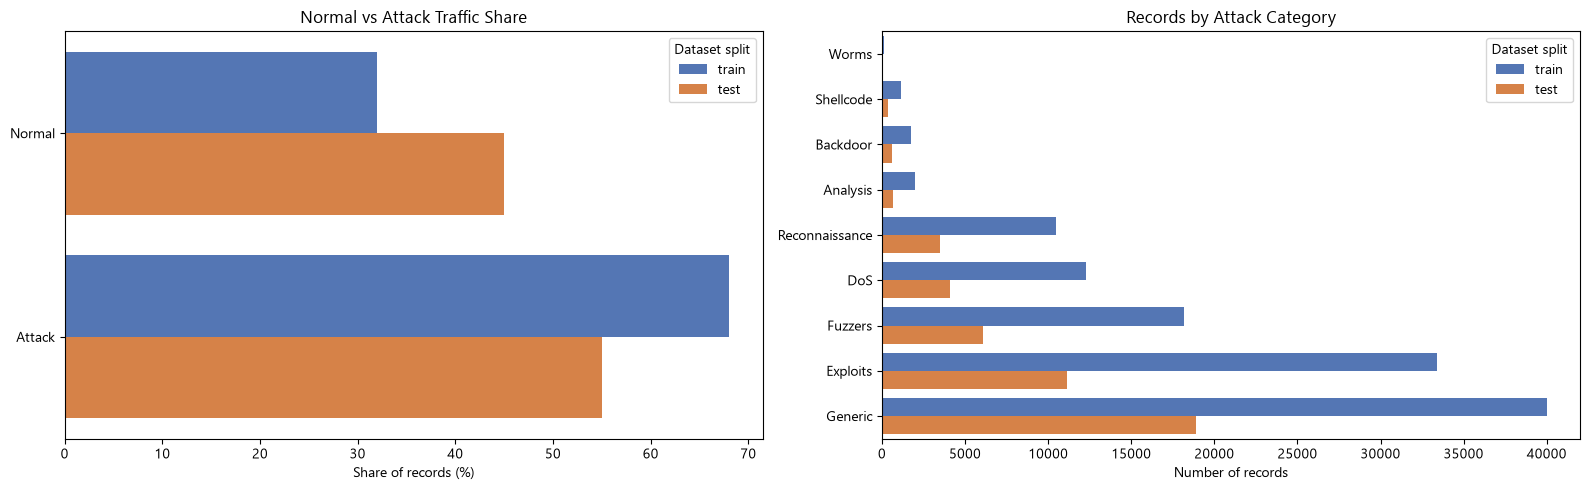

,split,label,rows,traffic,percent
0,test,0,37000,Normal,44.939999
1,test,1,45332,Attack,55.060001
2,train,0,56000,Normal,31.937767
3,train,1,119341,Attack,68.062233


บันทึกกราฟ: data-pipeline\UNSW-NB15\output\eda\graphs\02_categorical_features.png


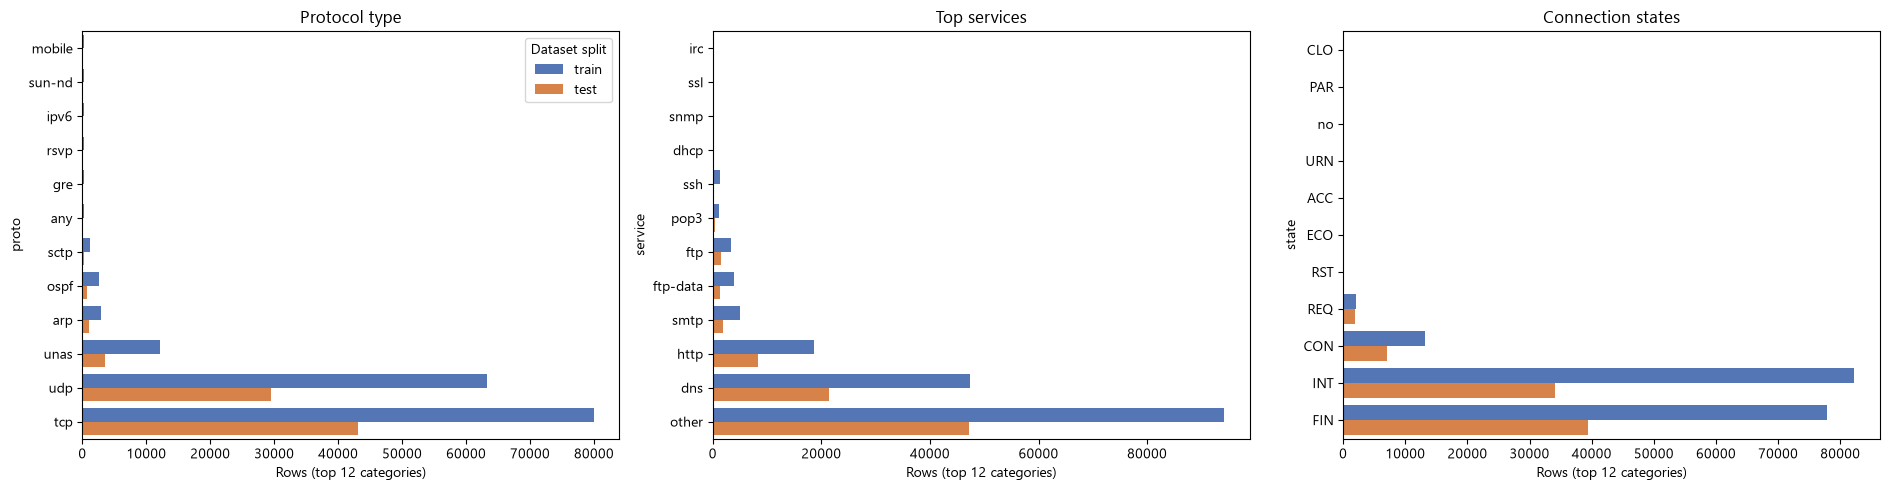

In [6]:
split_order = [name for name in ['train', 'test'] if name in eda_frames]
split_palette = {'train': '#4472C4', 'test': '#ED7D31'}

# กราฟคู่ label: คล้าย NSL-KDD โดยแยกสัดส่วน binary label กับจำนวน attack category
binary_plot = (full_labels.groupby(['split', 'label'], as_index=False)['rows'].sum())
binary_plot['traffic'] = binary_plot['label'].map({0: 'Normal', 1: 'Attack'}).fillna('Unknown')
binary_plot['percent'] = (100 * binary_plot['rows'] /
                         binary_plot.groupby('split')['rows'].transform('sum'))
attack_plot = full_labels.loc[
    full_labels['attack_cat'].astype(str).str.strip().str.lower().ne('normal')
].copy()
attack_order = (attack_plot.groupby('attack_cat')['rows'].sum()
               .sort_values().index.tolist())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=binary_plot, x='percent', y='traffic', hue='split',
            order=['Normal', 'Attack'], hue_order=split_order,
            palette=split_palette, ax=axes[0])
axes[0].set_title('Normal vs Attack Traffic Share')
axes[0].set_xlabel('Share of records (%)')
axes[0].set_ylabel('')
axes[0].legend(title='Dataset split')
sns.barplot(data=attack_plot, x='rows', y='attack_cat', hue='split',
            order=attack_order, hue_order=split_order,
            palette=split_palette, ax=axes[1])
axes[1].set_title('Records by Attack Category')
axes[1].set_xlabel('Number of records')
axes[1].set_ylabel('')
axes[1].legend(title='Dataset split')
plt.tight_layout()
save_eda_graph(fig, '01_labels_and_attack_categories.png')
plt.show()
display(binary_plot.sort_values(['split', 'label']))

# รูปแบบเดียวกับกราฟหมวดหมู่ 1 แถว 3 ช่องของ NSL-KDD: protocol, service และ state
categorical_to_plot = [name for name in ['proto', 'service', 'state']
                      if all(name in frame.columns for frame in eda_frames.values())]
if categorical_to_plot:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    plot_titles = {'proto': 'Protocol type', 'service': 'Top services',
                   'state': 'Connection states'}
    for ax, column in zip(axes, categorical_to_plot):
        all_counts = []
        for split_name, frame in eda_frames.items():
            values = frame[column].fillna('<missing>').astype(str)
            if column == 'service':
                values = values.replace({'-': 'other'})  # เปลี่ยนเฉพาะชื่อที่แสดง ไม่แก้ raw data
            counts = values.value_counts()
            all_counts.extend({'split': split_name, column: category, 'rows': int(count)}
                              for category, count in counts.items())
        plot_data = pd.DataFrame(all_counts)
        top_categories = (plot_data.groupby(column)['rows'].sum()
                         .nlargest(12).index.tolist())
        plot_data = plot_data.loc[plot_data[column].isin(top_categories)]
        category_order = (plot_data.groupby(column)['rows'].sum()
                         .sort_values().index.tolist())
        sns.barplot(data=plot_data, x='rows', y=column, hue='split',
                    order=category_order, hue_order=split_order,
                    palette=split_palette, ax=ax)
        ax.set_title(plot_titles[column])
        ax.set_xlabel('Rows (top 12 categories)')
        ax.set_ylabel(column)
        if ax is axes[0]:
            ax.legend(title='Dataset split')
        elif ax.get_legend() is not None:
            ax.get_legend().remove()
    plt.tight_layout()
    save_eda_graph(fig, '02_categorical_features.png')
    plt.show()

## 7. การกระจายตัวเลข ศูนย์ และค่าหางยาว

บล็อกนี้แสดงตารางสถิติจากข้อมูลเต็ม และ histogram 2 แถว × 4 ช่อง โดยมี 6 กราฟ: `dur` (ระยะเวลา), `sbytes` (ไบต์ต้นทาง), `dbytes` (ไบต์ปลายทาง), `spkts` (แพ็กเก็ตต้นทาง), `dpkts` (แพ็กเก็ตปลายทาง) และ `rate`; อีก 2 ช่องเว้นว่าง ตารางมี mean/median/ส่วนเบี่ยงเบนมาตรฐาน/ควอไทล์/เปอร์เซ็นต์ศูนย์/skew และจำนวน outlier ตามเกณฑ์ IQR ส่วนกราฟวาดจาก sample สูงสุด 25,000 แถวต่อ split โดยสุ่ม seed 42

วิธีอ่านกราฟ: แกนนอนคือ `log1p(x) = ln(1+x)` จึงไม่ใช่หน่วยเดิม; แกนตั้งเป็น density (ความหนาแน่น) ไม่ใช่จำนวนแถว เส้นสีน้ำเงินแทน Train และสีส้มแทน Test เส้น KDE ช่วยให้เห็นรูปทรงการกระจาย หากเส้นกระจุกทางซ้ายและทอดหางไปขวา แปลว่าค่าส่วนใหญ่อยู่ต่ำแต่มีค่าสูงจำนวนน้อย; หากเส้น Train/Test ต่างตำแหน่งหรือรูปร่าง แสดงว่า distribution ระหว่าง split ไม่เหมือนกัน ควรตรวจเรื่อง generalization เพิ่ม

วิธีอ่านตาราง: `median` คือค่ากลางที่ทนต่อค่าปลายสุดกว่า mean; `zero_percent` คือเปอร์เซ็นต์ที่เป็นศูนย์; `skew` บวกมากมักหมายถึงหางขวายาว; `iqr_outlier_rows/percent` นับค่าที่อยู่นอก Q1−1.5×IQR ถึง Q3+1.5×IQR ซึ่งเป็นธงทางสถิติ ไม่ใช่คำตัดสินว่าข้อมูลผิด ผลรันพบค่ากลางของหลายตัวแปรต่ำกว่า mean มาก เช่น bytes และ rate มีหาง/ความเบ้สูง จึงควรใช้ log transform หรือ scaling ที่เหมาะสมในการทดลอง แต่ห้ามลบ outlier อัตโนมัติ กราฟเป็นการแสดงผลเท่านั้น ไม่แก้หรือ clip raw data

,split,feature,count,mean,median,std,min,q1,q3,max,zero_percent,skew,iqr_outlier_rows,iqr_outlier_percent
51,test,dload,82332,6.305470e+05,2.112951e+03,2.393001e+06,0.0,0.000000,1.585808e+04,2.082111e+07,43.741194,4.753901e+00,18112,21.998737
74,test,ct_dst_src_ltm,82332,7.456360e+00,3.000000e+00,1.141519e+01,1.0,1.000000,6.000000e+00,6.300000e+01,0.000000,2.189041e+00,12789,15.533450
46,test,dbytes,82332,1.323379e+04,1.780000e+02,1.514715e+05,0.0,0.000000,9.560000e+02,1.465753e+07,43.732692,5.255039e+01,12308,14.949230
65,test,smean,82332,1.395286e+02,6.500000e+01,2.084721e+02,24.0,57.000000,1.000000e+02,1.504000e+03,0.000000,3.544111e+00,11928,14.487684
72,test,ct_src_dport_ltm,82332,4.928898e+00,1.000000e+00,8.389545e+00,1.0,1.000000,4.000000e+00,5.900000e+01,0.000000,2.856818e+00,11476,13.938687
53,test,dloss,82332,6.308556e+00,0.000000e+00,5.570802e+01,0.0,0.000000,2.000000e+00,5.507000e+03,50.046155,5.446565e+01,11272,13.690910
73,test,ct_dst_sport_ltm,82332,3.663011e+00,1.000000e+00,5.915386e+00,1.0,1.000000,3.000000e+00,3.800000e+01,0.000000,2.506801e+00,10907,13.247583
71,test,ct_dst_ltm,82332,5.744923e+00,2.000000e+00,8.418112e+00,1.0,1.000000,6.000000e+00,5.900000e+01,0.000000,2.667001e+00,10479,12.727736
43,test,spkts,82332,1.866647e+01,6.000000e+00,1.339164e+02,1.0,2.000000,1.200000e+01,1.064600e+04,0.000000,4.774778e+01,10196,12.384006
69,test,ct_srv_src,82332,9.546604e+00,5.000000e+00,1.109029e+01,1.0,2.000000,1.100000e+01,6.300000e+01,0.000000,1.856368e+00,10093,12.258903


บันทึกกราฟ: data-pipeline\UNSW-NB15\output\eda\graphs\03_numeric_distributions.png


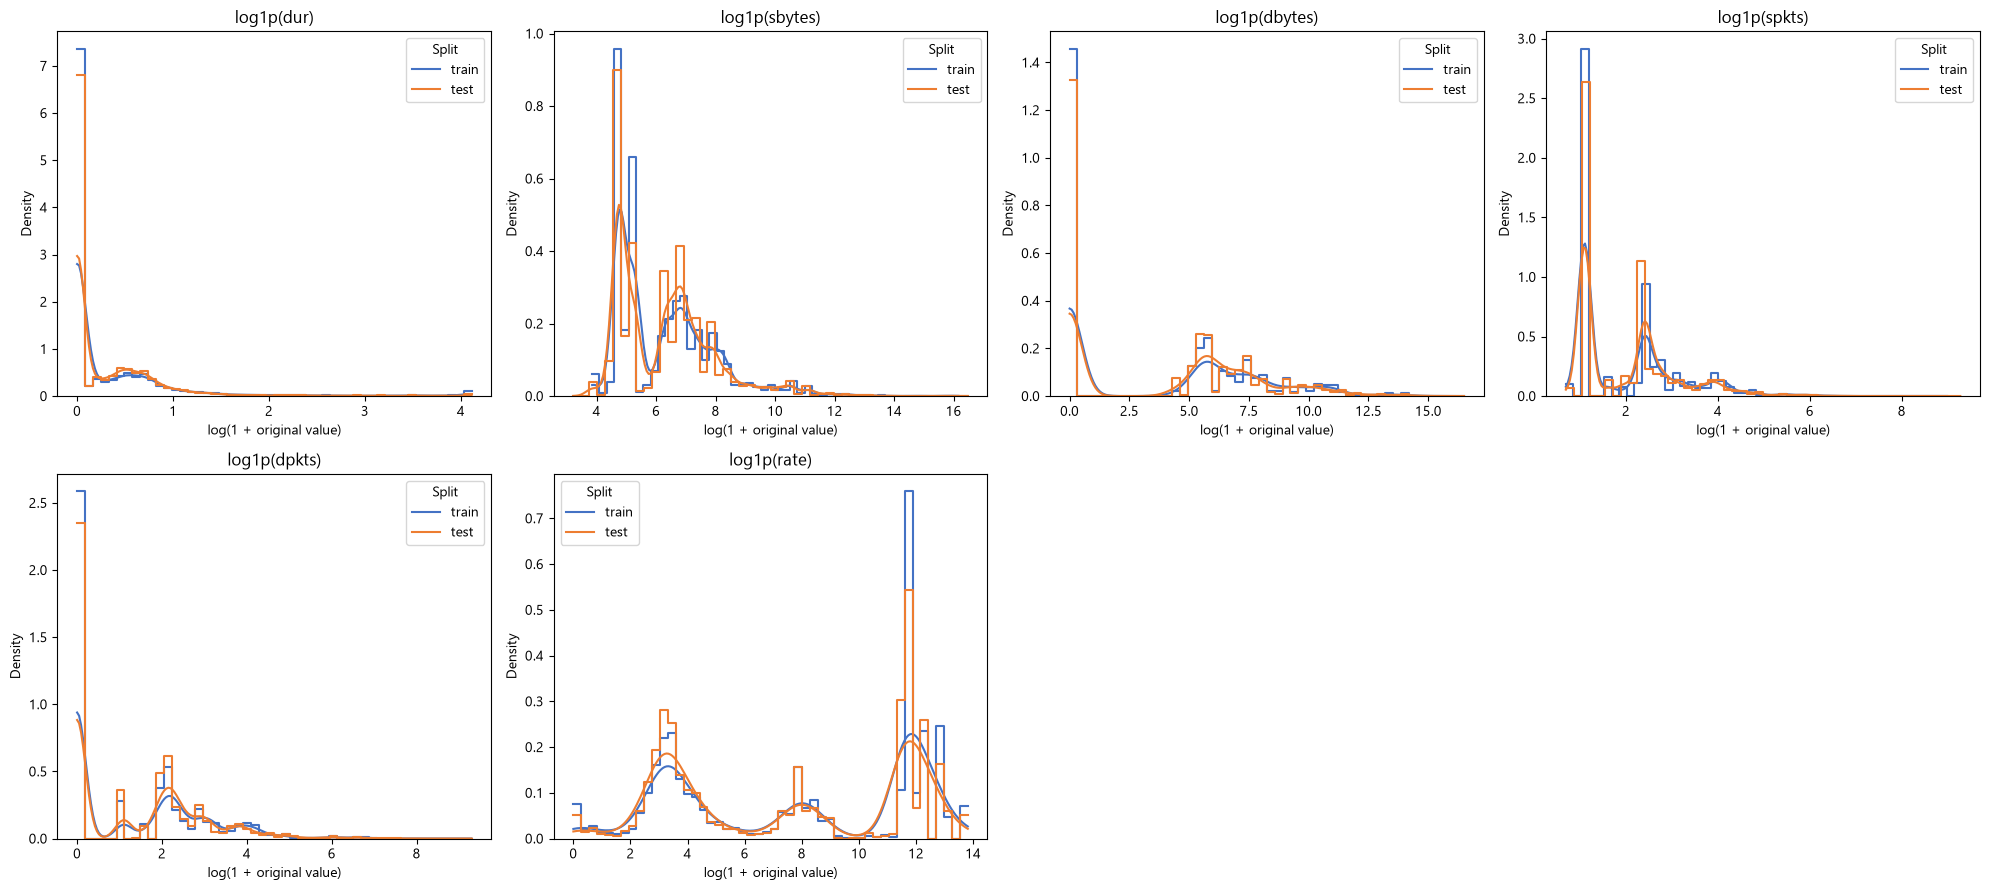

In [7]:
numeric_rows = []
for split_name, frame in eda_frames.items():
    for column in frame.select_dtypes(include='number').columns:
        values = frame[column].dropna()
        if values.empty:
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        spread = q3 - q1
        outlier_count = int(((values < q1 - 1.5 * spread) |
                             (values > q3 + 1.5 * spread)).sum())
        numeric_rows.append({
            'split': split_name, 'feature': column, 'count': len(values),
            'mean': values.mean(), 'median': values.median(), 'std': values.std(),
            'min': values.min(), 'q1': q1, 'q3': q3, 'max': values.max(),
            'zero_percent': 100 * values.eq(0).mean(), 'skew': values.skew(),
            'iqr_outlier_rows': outlier_count,
            'iqr_outlier_percent': 100 * outlier_count / len(values),
        })
numeric_full_summary = pd.DataFrame(numeric_rows)
display(numeric_full_summary.sort_values(['split', 'iqr_outlier_percent'],
                                         ascending=[True, False]).head(40))

plot_columns = [column for column in ['dur', 'sbytes', 'dbytes', 'spkts', 'dpkts', 'rate']
                if all(column in frame.columns for frame in eda_frames.values())]
plot_frames = {name: frame.sample(n=min(25_000, len(frame)), random_state=42)
               for name, frame in eda_frames.items()}
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, column in zip(axes.flat, plot_columns):
    for split_name in split_order:
        values = pd.to_numeric(plot_frames[split_name][column], errors='coerce')
        values = values.dropna().clip(lower=0)
        sns.histplot(np.log1p(values), bins=50, kde=True, stat='density',
                    element='step', fill=False, common_norm=False,
                    color=split_palette[split_name], label=split_name, ax=ax)
    ax.set_title(f'log1p({column})')
    ax.set_xlabel('log(1 + original value)')
    ax.set_ylabel('Density')
    ax.legend(title='Split')
for ax in axes.flat[len(plot_columns):]:
    ax.axis('off')
plt.tight_layout()
save_eda_graph(fig, '03_numeric_distributions.png')
plt.show()

## 8. เปรียบเทียบ Normal กับ Attack และความสัมพันธ์ของตัวเลข

บล็อกนี้มีตารางเปรียบเทียบ, boxplot 2×3 และ heatmap พร้อมตาราง correlation: ตารางแรกคำนวณจำนวนตัวอย่าง mean/median ของ `dur`, `sbytes`, `dbytes`, `spkts`, `dpkts` แยก Train/Test และ label; boxplot ใช้ Train sample สูงสุด 25,000 แถว เปรียบเทียบ Normal/Attack สำหรับ 6 ช่อง (`dur`, `sbytes`, `dbytes`, `spkts`, `dpkts`, `rate`) โดยใช้ `log1p` และซ่อนจุด fliers; heatmap ใช้ Train เลือก 12 ตัวแปรที่มี absolute Pearson correlation กับ `label` สูงสุด แล้วแสดงความสัมพันธ์ระหว่างตัวแปรเหล่านั้นและ label ส่วนตารางท้ายเรียงค่าสัมบูรณ์จากมากไปน้อย

วิธีอ่าน boxplot: เส้นกลางกล่องคือ median, กล่องคือช่วงเปอร์เซ็นไทล์ 25–75 และหนวดแสดงช่วงตามกติกา boxplot; สีเขียวคือ Normal สีส้มคือ Attack แกนเป็น `log1p` ของค่าที่ไม่ติดลบ จึงใช้เทียบรูปร่าง/ตำแหน่ง ไม่อ่านเป็นหน่วยดิบ ตารางก่อนกราฟใช้ข้อมูลเต็มและช่วยยืนยัน median ได้ เช่นใน Train ค่า median `sbytes` คือ Normal 1,470 เทียบ Attack 200; `dbytes` คือ 1,112 เทียบ 0; `spkts` คือ 12 เทียบ 2; `dpkts` คือ 10 เทียบ 0 จึงเห็นการกระจายบางตัวต่างกันชัดในชุดนี้ แต่กลุ่มยังอาจซ้อนกัน และตัวอย่างในกราฟเป็นเพียง sample

วิธีอ่าน heatmap: แต่ละช่องเป็น Pearson correlation อยู่ระหว่าง −1 ถึง +1; สี/ความเข้มบอกทิศทางและขนาด ครึ่งบนถูกซ่อนเพราะซ้ำกับครึ่งล่าง ตารางถัดจากรูปแสดง absolute correlation กับ label ซึ่งไม่มีเครื่องหมายทิศทาง ตารางจริงพบ `id` สูงสุด (0.727), ตามด้วย `sttl` (0.693) และ `ct_state_ttl` (0.578) ข้อควรระวังสำคัญคือ `id` เป็นรหัส record ไม่ใช่พฤติกรรมเครือข่าย ความสัมพันธ์สูงอาจเกิดจากลำดับการบันทึกหรือการจัดชุดข้อมูล จึงไม่ควรส่ง `id` เข้าโมเดลโดยไม่ตรวจสอบ/ควรตัดออกจาก predictor

การแยก boxplot ตาม label และการคำนวณ correlation ใช้ label เพื่อวิเคราะห์หลังมีข้อมูลแล้วเท่านั้น ไม่ใช่เหตุและผล และไม่ใช่การฝึก Isolation Forest แบบ supervised ความสัมพันธ์ที่เห็นเป็นเพียงจุดเริ่มตรวจต่อ ไม่รับประกันว่าจะใช้ได้กับข้อมูลจากบริษัทหรือเครือข่ายอื่น

,split,label,traffic,feature,rows,median,mean
0,train,0,Normal,dur,56000,0.038602,1.017177
1,train,1,Attack,dur,119341,0.000009,1.519969
2,train,0,Normal,sbytes,56000,1470.000000,4105.702929
3,train,1,Attack,sbytes,119341,200.000000,11068.655357
4,train,0,Normal,dbytes,56000,1112.000000,31049.463143
5,train,1,Attack,dbytes,119341,0.000000,7364.456256
6,train,0,Normal,spkts,56000,12.000000,30.725482
7,train,1,Attack,spkts,119341,2.000000,15.405946
8,train,0,Normal,dpkts,56000,10.000000,38.057696
9,train,1,Attack,dpkts,119341,0.000000,10.012619


บันทึกกราฟ: data-pipeline\UNSW-NB15\output\eda\graphs\04_normal_vs_attack_boxplots.png


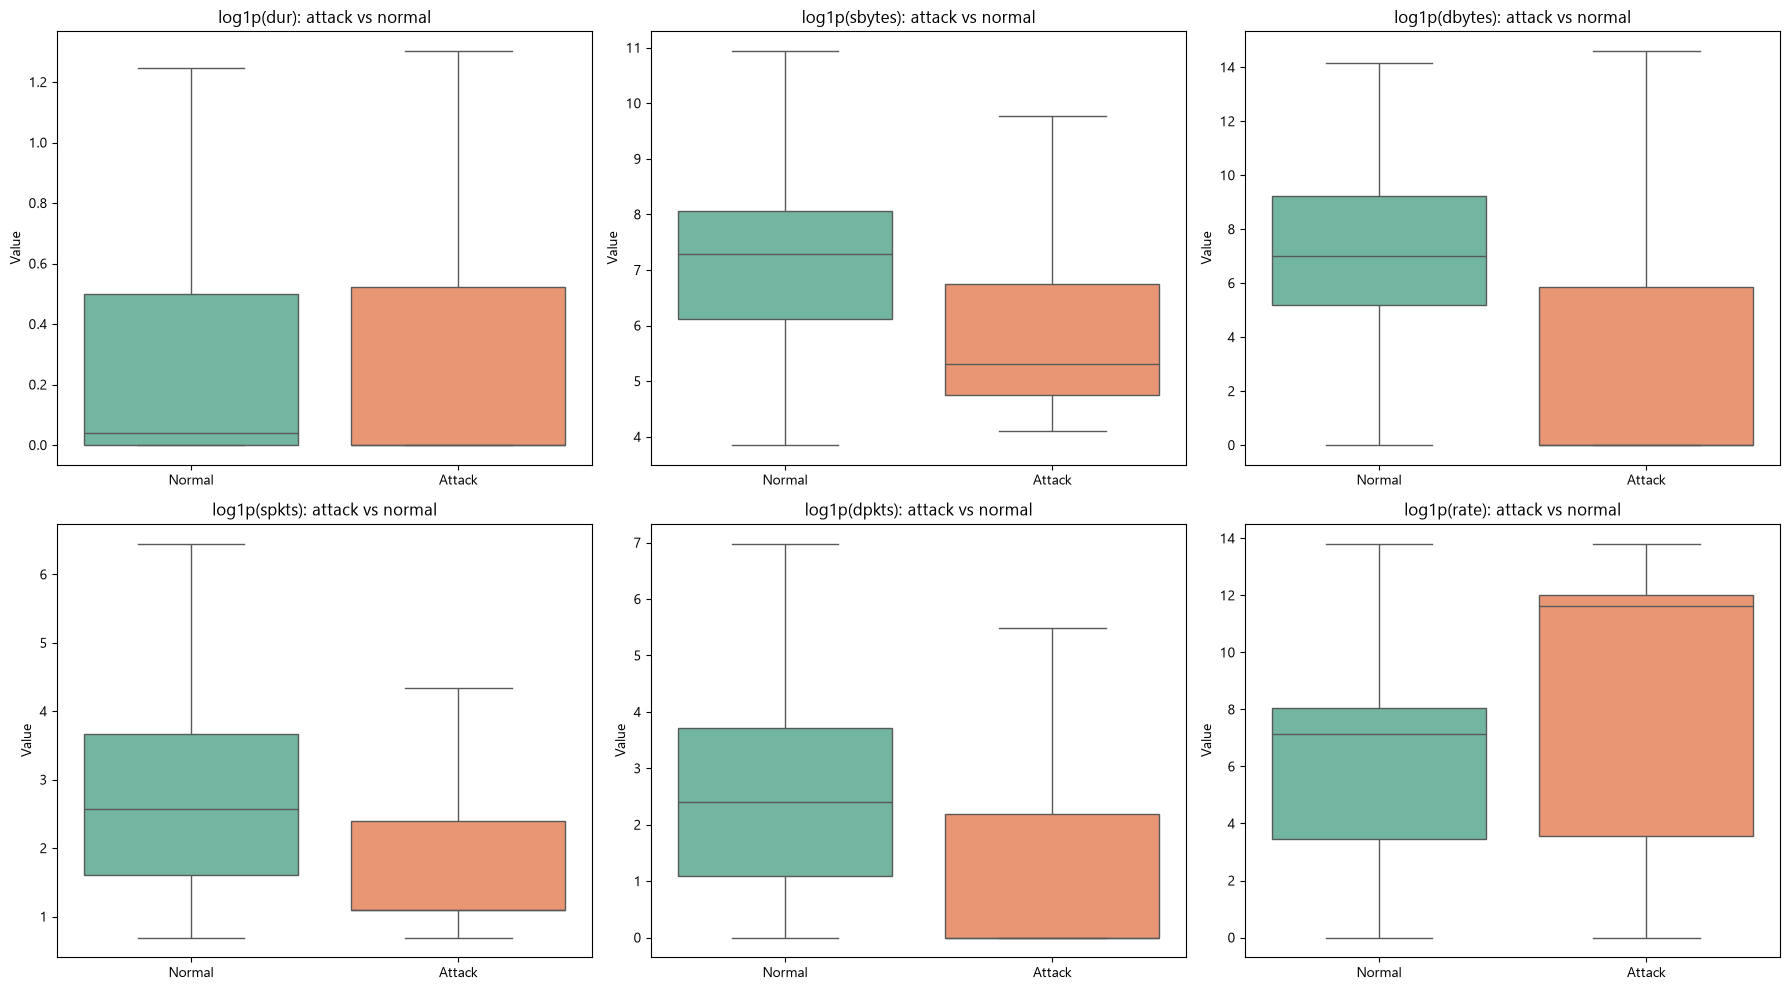

บันทึกกราฟ: data-pipeline\UNSW-NB15\output\eda\graphs\05_numeric_correlation_heatmap.png


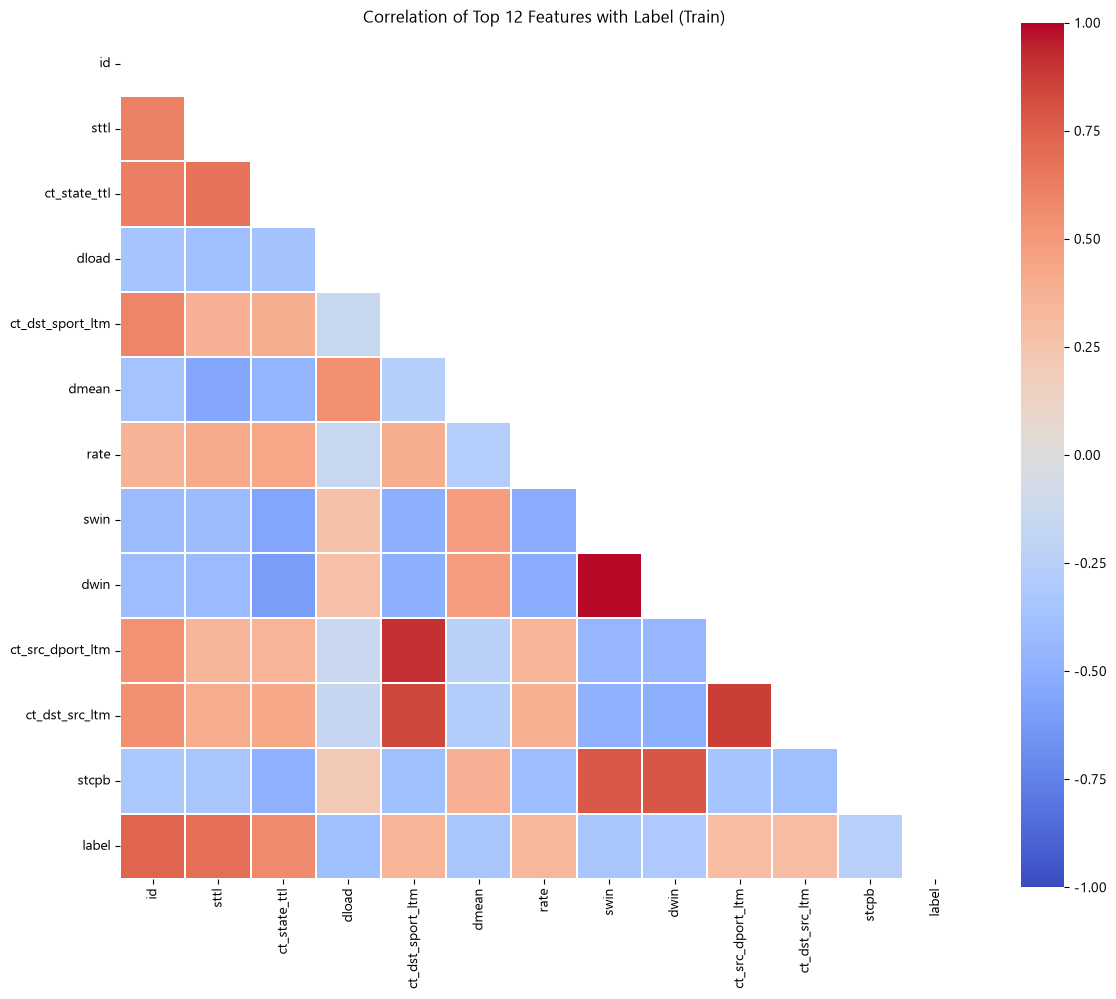

,absolute_pearson_correlation_with_label
id,0.727173
sttl,0.692741
ct_state_ttl,0.577704
dload,0.393739
ct_dst_sport_ltm,0.357213
dmean,0.341806
rate,0.337979
swin,0.333633
dwin,0.319626
ct_src_dport_ltm,0.305579


In [8]:
comparison_rows = []
for split_name, frame in eda_frames.items():
    needed = {'label', 'dur', 'sbytes', 'dbytes', 'spkts', 'dpkts'}
    if not needed.issubset(frame.columns):
        continue
    for column in ['dur', 'sbytes', 'dbytes', 'spkts', 'dpkts']:
        values = pd.to_numeric(frame[column], errors='coerce')
        for label_value, group in frame.groupby('label'):
            selected = values.loc[group.index].dropna()
            comparison_rows.append({
                'split': split_name, 'label': label_value,
                'traffic': 'Attack' if int(float(label_value)) == 1 else 'Normal',
                'feature': column, 'rows': len(selected),
                'median': selected.median(), 'mean': selected.mean(),
            })
display(pd.DataFrame(comparison_rows))

train = eda_frames['train'].copy()
if 'label' in train.columns:
    train['traffic'] = train['label'].map({0: 'Normal', 1: 'Attack'}).fillna('Unknown')
    plot_train = train.sample(n=min(25_000, len(train)), random_state=42).copy()
    plot_train['traffic'] = plot_train['label'].map({0: 'Normal', 1: 'Attack'}).fillna('Unknown')
    compare_columns = [column for column in ['dur', 'sbytes', 'dbytes', 'spkts', 'dpkts', 'rate']
                       if column in plot_train.columns]
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    traffic_palette = {'Normal': '#66c2a5', 'Attack': '#fc8d62'}
    for ax, column in zip(axes.flat, compare_columns):
        plot_values = pd.to_numeric(plot_train[column], errors='coerce').clip(lower=0)
        box_data = pd.DataFrame({'traffic': plot_train['traffic'], 'value': np.log1p(plot_values)})
        sns.boxplot(data=box_data, x='traffic', y='value', hue='traffic',
                    order=['Normal', 'Attack'], hue_order=['Normal', 'Attack'],
                    palette=traffic_palette, legend=False, showfliers=False, ax=ax)
        ax.set_title(f'log1p({column}): attack vs normal')
        ax.set_xlabel('')
        ax.set_ylabel('Value')
    for ax in axes.flat[len(compare_columns):]:
        ax.axis('off')
    plt.tight_layout()
    save_eda_graph(fig, '04_normal_vs_attack_boxplots.png')
    plt.show()

    numeric_train = train.select_dtypes(include='number').copy()
    if 'label' in numeric_train.columns and numeric_train.shape[1] > 1:
        correlations = numeric_train.corr(numeric_only=True)['label'].drop('label').abs().sort_values(ascending=False)
        selected_features = correlations.head(12).index.tolist() + ['label']
        correlation_matrix = numeric_train[selected_features].corr()
        mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
        plt.figure(figsize=(12, 10))
        sns.heatmap(correlation_matrix, mask=mask, cmap='coolwarm', center=0,
                    vmin=-1, vmax=1, square=True, linewidths=0.25, annot=False)
        plt.title('Correlation of Top 12 Features with Label (Train)')
        plt.tight_layout()
        save_eda_graph(plt.gcf(), '05_numeric_correlation_heatmap.png')
        plt.show()
        display(correlations.head(12).rename('absolute_pearson_correlation_with_label').to_frame())

## 9. สรุปสิ่งที่ควรนำไปตัดสินใจก่อนขั้นถัดไป

ผล EDA ใช้ตั้งกฎ cleansing และเลือกวิธีทดลอง ไม่ควรลบ outlier เพียงเพราะอยู่นอก IQR เพราะการโจมตีอาจเป็นเหตุการณ์หายากจริง ให้ตรวจ missing, คอลัมน์คงที่, label ที่ไม่สมดุล และความต่างระหว่าง Train/Test ก่อนสร้างข้อมูลสำหรับโมเดล

In [9]:
print('ข้อสังเกตจากข้อมูลเต็ม:')
for _, row in full_overview.iterrows():
    print(f"- {row['split']}: {row['rows']:,} แถว, {row['columns']} คอลัมน์, แถวซ้ำ {row['duplicate_rows']:,}, ช่อง missing {row['missing_cells']:,}")
if not full_labels.empty:
    print('- label 0 หมายถึง normal และ label 1 หมายถึง attack ใน binary target ของ UNSW; attack_cat เป็นคำอธิบายชนิดย่อย')
if not schema_full.loc[schema_full['constant_column']].empty:
    print('- พบคอลัมน์คงที่; ตรวจว่าควรตัดออกจาก feature profile หรือไม่ แต่อย่าแก้ raw')
print('- ความสัมพันธ์และ boxplot เป็นเพียงรูปแบบร่วม ไม่ใช่เหตุผลเชิงสาเหตุ และ label จะใช้ประเมินภายหลัง ไม่ใช้ fit Isolation Forest แบบ unsupervised')
full_overview.to_csv(output_dir / 'eda_full_overview.csv', index=False)
schema_full.to_csv(output_dir / 'eda_full_schema_quality.csv', index=False)
full_labels.to_csv(output_dir / 'eda_full_label_summary.csv', index=False)
numeric_full_summary.to_csv(output_dir / 'eda_full_numeric_summary.csv', index=False)
print('บันทึกตารางสรุปเต็มไว้ที่:', output_dir)
print('โฟลเดอร์รูปกราฟ:', graph_output_dir)

ข้อสังเกตจากข้อมูลเต็ม:
- train: 175,341 แถว, 45 คอลัมน์, แถวซ้ำ 0, ช่อง missing 0
- test: 82,332 แถว, 45 คอลัมน์, แถวซ้ำ 0, ช่อง missing 0
- label 0 หมายถึง normal และ label 1 หมายถึง attack ใน binary target ของ UNSW; attack_cat เป็นคำอธิบายชนิดย่อย
- ความสัมพันธ์และ boxplot เป็นเพียงรูปแบบร่วม ไม่ใช่เหตุผลเชิงสาเหตุ และ label จะใช้ประเมินภายหลัง ไม่ใช้ fit Isolation Forest แบบ unsupervised
บันทึกตารางสรุปเต็มไว้ที่: C:\Users\Windows 10\Desktop\CSI_ML_Final\data-pipeline\UNSW-NB15\output\reports
โฟลเดอร์รูปกราฟ: C:\Users\Windows 10\Desktop\CSI_ML_Final\data-pipeline\UNSW-NB15\output\eda\graphs
